# Task 3: Basic Data Visualization
**Dataset:** House prediction data
**Goal:** Create bar plots, line charts and scatter plots, add clear labels, titles and legends, and save the plots as images.
**Tools:** Python, matplotlib, seaborn.

# Load the data
I import the tools and load the house data into a table called df.

In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("plots", exist_ok=True)

names = ["crim", "zn", "indus", "chas", "nox", "rm", "age",
         "dis", "rad", "tax", "ptratio", "b", "lstat", "medv"]

df = pd.read_csv("../datasets/4) house Prediction Data Set.csv",
                 sep=r"\s+", header=None, names=names)
df.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


## Look at the data
I check the size of the table, the column names and types, and if any values are missing.

In [4]:
print(df.shape)
df.info()

(506, 14)
<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       506 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    float64
 10  ptratio  506 non-null    float64
 11  b        506 non-null    float64
 12  lstat    506 non-null    float64
 13  medv     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


The data has 506 rows and 14 columns. All columns are numbers and none have missing values, so no cleaning is needed.

In [5]:
print(df.isnull().sum())
df.describe()

crim       0
zn         0
indus      0
chas       0
nox        0
rm         0
age        0
dis        0
rad        0
tax        0
ptratio    0
b          0
lstat      0
medv       0
dtype: int64


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


## Choose the columns
I separate the number columns from the text columns, so I know what to plot.


In [9]:
num_cols = df.select_dtypes(include="number").columns
text_cols = df.select_dtypes(exclude="number").columns

print("Number columns:", list(num_cols))
print("Text columns:", list(text_cols))

Number columns: ['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax', 'ptratio', 'b', 'lstat', 'medv']
Text columns: []


All 14 columns are numbers, so there are no text columns to group by. For the bar plots I will make groups from the number columns instead.

## Bar plots
A bar plot compares groups. First I compare the average house price for homes with different numbers of rooms.

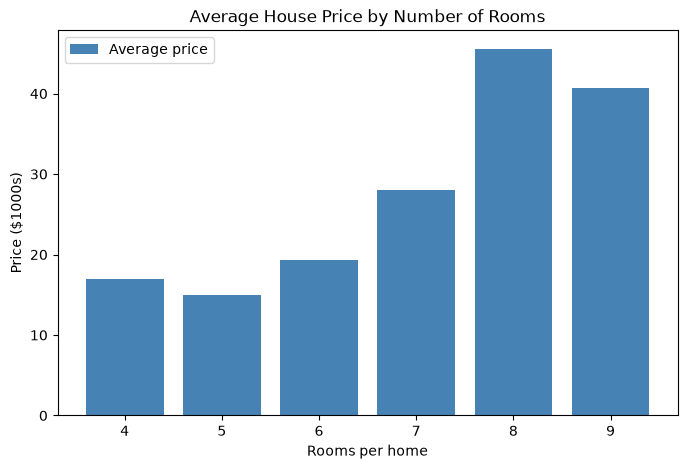

In [10]:
df["rooms"] = df["rm"].round().astype(int)

avg_price = df.groupby("rooms")["medv"].mean()

plt.figure(figsize=(8, 5))
plt.bar(avg_price.index, avg_price.values, color="steelblue", label="Average price")
plt.title("Average House Price by Number of Rooms")
plt.xlabel("Rooms per home")
plt.ylabel("Price ($1000s)")
plt.legend()

plt.savefig("plots/bar_price_by_rooms.png")
plt.show()

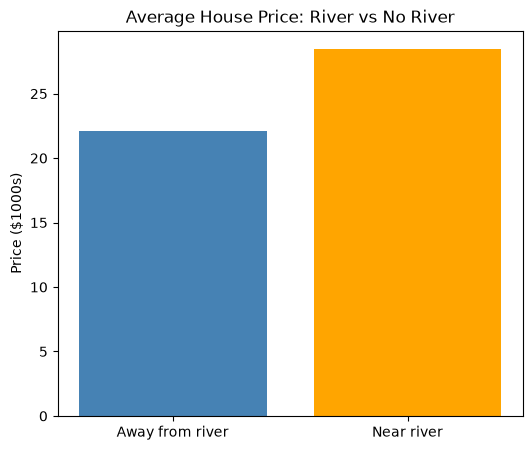

In [11]:
river_price = df.groupby("chas")["medv"].mean()

plt.figure(figsize=(6, 5))
plt.bar(["Away from river", "Near river"], river_price.values, color=["steelblue", "orange"])
plt.title("Average House Price: River vs No River")
plt.ylabel("Price ($1000s)")

plt.savefig("plots/bar_price_river.png")
plt.show()

## Scatter plots
A scatter plot shows how two numbers are linked. Each dot is one area.

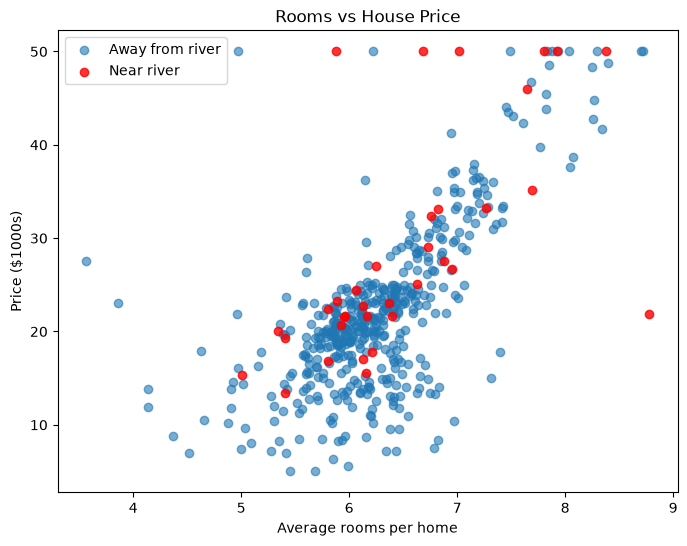

In [12]:
near = df[df["chas"] == 1]
away = df[df["chas"] == 0]

plt.figure(figsize=(8, 6))
plt.scatter(away["rm"], away["medv"], label="Away from river", alpha=0.6)
plt.scatter(near["rm"], near["medv"], label="Near river", color="red", alpha=0.8)
plt.title("Rooms vs House Price")
plt.xlabel("Average rooms per home")
plt.ylabel("Price ($1000s)")
plt.legend()

plt.savefig("plots/scatter_rooms_price.png")
plt.show()

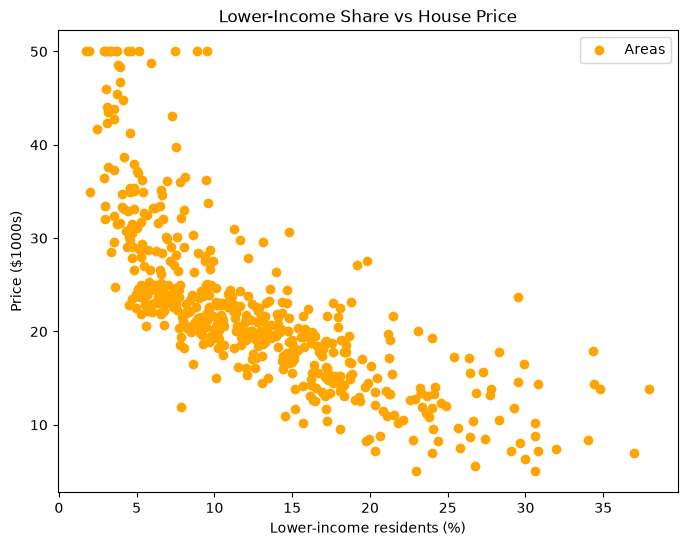

In [13]:
plt.figure(figsize=(8, 6))
plt.scatter(df["lstat"], df["medv"], color="orange", label="Areas")
plt.title("Lower-Income Share vs House Price")
plt.xlabel("Lower-income residents (%)")
plt.ylabel("Price ($1000s)")
plt.legend()

plt.savefig("plots/scatter_lstat_price.png")
plt.show()

## Line chart
A line chart shows a trend. This data has no dates, so I use the number of rooms as the ordered axis.

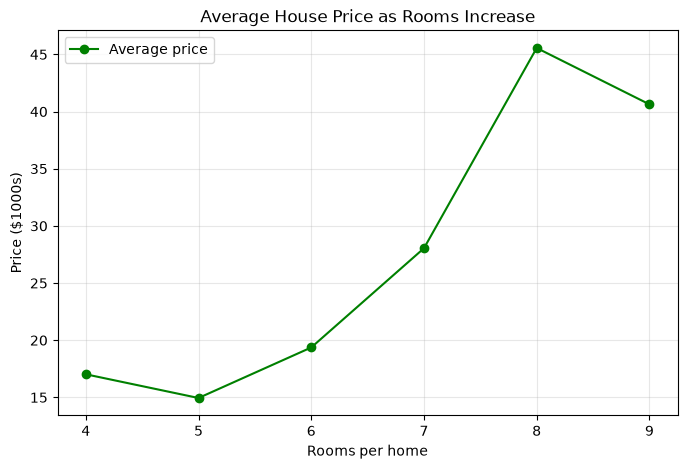

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(avg_price.index, avg_price.values, marker="o", color="green", label="Average price")
plt.title("Average House Price as Rooms Increase")
plt.xlabel("Rooms per home")
plt.ylabel("Price ($1000s)")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig("plots/line_price_by_rooms.png")
plt.show()

## Summary
- The data has 506 rows and 14 columns, with no missing values.
- The bar plots showed that the finding is that as the room number increases, the price also increases therefore the bar chart shows an increase from the left to the right.
and for the rooms near the river are more expensive than the rooms far from the river.
- The scatter plots showed that the rooms away from the river are much more in number and less priced according to average than the rooms near the river that are few and more priced.
then for the lower income residents their number is more concentrated on the left part of the graph than the right.
- The line chart showed that the average price increases left to right as the number of rooms per home also increases.
- Every chart has a title, axis labels and a legend, and was saved as an image in the plots folder.